# 🫀 Build Your First AI Healthcare App — Beginner Track
**Project:** a heart-failure risk predictor with a working web app, built on real clinical records.

**How this notebook works**
- It runs top-to-bottom as-is. **Run every cell first** (Runtime → Run all, or Shift+Enter), then come back and tinker.
- Look for **👈 YOUR TURN** markers. Those are the only places you need to edit.
- Checkpoints tell you where you should be at each time mark.

> ⚠️ Educational project only. It is **not** medical advice and must never be used to make real clinical decisions.

**Data:** *Heart Failure Clinical Records* (UCI ML Repository, CC BY 4.0). 299 patients with heart failure, 12 clinical features, outcome = did the patient die during follow-up.
Citation: Chicco & Jurman (2020), *BMC Medical Informatics and Decision Making* 20:16.

## ⏱ Minutes 10–18 · Setup and meet the data

In [ ]:
!pip -q install ucimlrepo gradio

In [ ]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             roc_auc_score, confusion_matrix)

pd.set_option("display.max_columns", 30)
SEED = 42  # keeps results repeatable

In [ ]:
def load_heart_failure():
    """Try the UCI repository first; fall back to a CSV you upload (organizers will share one)."""
    try:
        from ucimlrepo import fetch_ucirepo
        d = fetch_ucirepo(id=519)
        df = d.data.features.copy()
        df["death_event"] = d.data.targets.iloc[:, 0].values
        print("Loaded from the UCI repository ✅")
        return df
    except Exception as e:
        print(f"UCI download failed ({type(e).__name__}). Looking for a local CSV...")
        path = "heart_failure_clinical_records_dataset.csv"
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"Upload {path} using the Files panel (folder icon on the left), then re-run this cell.")
        df = pd.read_csv(path)
        df.columns = [c.lower() for c in df.columns]
        print("Loaded from local CSV ✅")
        return df

df = load_heart_failure()

needed = {"age", "ejection_fraction", "serum_creatinine", "serum_sodium", "high_blood_pressure",
          "anaemia", "diabetes", "smoking", "time", "death_event"}
assert needed <= set(df.columns), f"Unexpected columns. Found: {list(df.columns)}"
print(f"Patients: {len(df)} | Columns: {df.shape[1]} | Missing values: {int(df.isna().sum().sum())}")
print(f"Died during follow-up: {df['death_event'].mean():.1%}")
df.head()

Loaded from the UCI repository ✅
Patients: 299 | Columns: 13 | Missing values: 0
Died during follow-up: 32.1%


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


### Dataset quality and feature analysis

Before fitting a classifier, inspect missing values, duplicated records, outcome balance, and the distributions of key clinical measurements. This helps identify data issues and class imbalance. These are descriptive checks, **not clinical validation**.


In [ ]:
# Basic data quality report
quality_report = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique_values": df.nunique(),
})
print("Duplicate patient rows:", int(df.duplicated().sum()))
print("Missing values overall:", int(df.isna().sum().sum()))
display(quality_report)

# Class imbalance matters: a model can appear accurate by favoring the majority class.
outcome_counts = df["death_event"].value_counts().sort_index()
outcome_summary = pd.DataFrame({
    "patients": outcome_counts,
    "percentage": (outcome_counts / len(df) * 100).round(1),
})
outcome_summary.index = outcome_summary.index.map({0: "Survived follow-up", 1: "Died during follow-up"})
display(outcome_summary)

fig, ax = plt.subplots(figsize=(6, 3.5))
outcome_summary["patients"].plot.bar(ax=ax, rot=0)
ax.set(title="Outcome distribution in the dataset", xlabel="Recorded outcome", ylabel="Patients")
plt.tight_layout()
plt.show()


In [ ]:
# Summarize key numeric features by recorded outcome.
clinical_features = ["age", "ejection_fraction", "serum_creatinine", "serum_sodium"]
display(df.groupby("death_event")[clinical_features].agg(["median", "mean"]).round(2))

# Descriptive only: these group differences do not establish causation.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, feature in zip(axes, clinical_features[1:]):
    ax.boxplot([df.loc[df["death_event"] == group, feature].dropna()
                for group in (0, 1)], labels=["Survived", "Died"])
    ax.set_title(feature.replace("_", " ").title())
    ax.set_ylabel(feature.replace("_", " "))
plt.tight_layout()
plt.show()


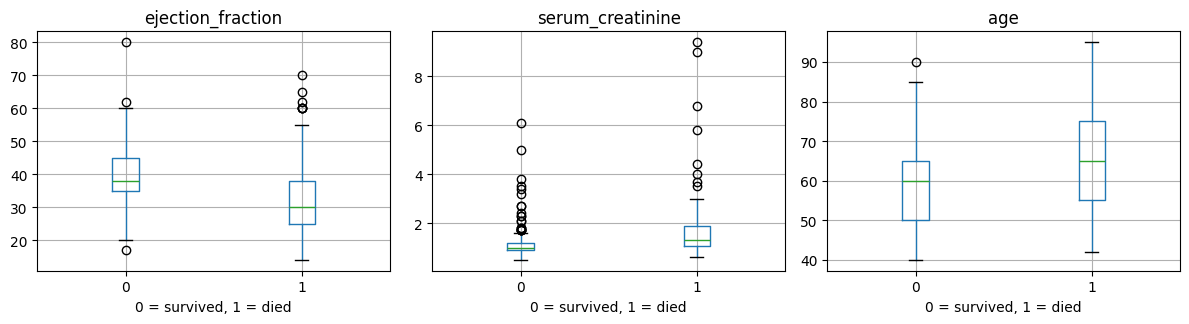

In [ ]:
# Three features a cardiologist would look at first, split by outcome
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, ["ejection_fraction", "serum_creatinine", "age"]):
    df.boxplot(column=col, by="death_event", ax=ax)
    ax.set_title(col); ax.set_xlabel("0 = survived, 1 = died")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Quick glossary**
- **Ejection fraction (EF):** % of blood the heart pumps out per beat. Lower = weaker heart.
- **Serum creatinine:** a kidney-function marker. Higher = kidneys struggling.

💬 *Talk to your neighbor: which group looks different in each plot?*

✅ **Checkpoint 1 (≈ minute 18):** data loaded, plots visible.

## ⏱ Minutes 18–28 · Prepare the data (and dodge a classic trap)

This dataset has a column called `time` = the patient's **follow-up period in days**. Patients who died have shorter follow-up, so `time` partly *encodes the outcome*. At the moment a doctor would actually want a prediction, that number doesn't exist yet. Using it is called **data leakage**: great test scores, useless in real life.

We exclude it by default.

In [ ]:
USE_FOLLOWUP_TIME = False   # 👈 YOUR TURN #1: after the whole notebook works, set True, re-run, and compare ROC-AUC. Why is it "cheating"?

target = "death_event"
features = [c for c in df.columns if c != target and (USE_FOLLOWUP_TIME or c != "time")]
X, y = df[features], df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"{len(features)} features | {len(X_train)} train patients | {len(X_test)} test patients")

11 features | 239 train patients | 60 test patients


## ⏱ Minutes 28–36 · Train models and evaluate them like a clinician
**First, a sanity check:** a "model" that predicts *everyone survives*.

In [ ]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
p = dummy.predict(X_test)
print(f"'Everyone survives' → accuracy {accuracy_score(y_test, p):.0%}, "
      f"but it catches {recall_score(y_test, p):.0%} of patients who die.")

'Everyone survives' → accuracy 68%, but it catches 0% of patients who die.


Accuracy looks decent and the model is **useless**. In medicine we care about:
- **Recall (sensitivity):** of the patients who *did* die, what fraction did we flag?
- **Precision:** of the patients we flagged, what fraction truly died?
- **ROC-AUC:** how well the model *ranks* risky patients above safe ones (0.5 = coin flip, 1.0 = perfect).

In [ ]:
models = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=SEED),
}
# models["Gradient Boosting"] = GradientBoostingClassifier(random_state=SEED)   # 👈 YOUR TURN #2a: uncomment to add a third model

def evaluate(model, name, threshold=0.5):
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_test, pred),
            "recall (deaths caught)": recall_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, proba)}

results = pd.DataFrame([evaluate(m, n) for n, m in models.items()]).set_index("model").round(3)
results

,accuracy,recall (deaths caught),precision,ROC-AUC
model,,,,
Logistic Regression,0.700,0.526,0.526,0.734
Random Forest,0.733,0.526,0.588,0.788


With only 60 test patients, one lucky split can mislead you. **Cross-validation** repeats the split 5 times and averages:

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    s = cross_validate(m, X, y, cv=cv, scoring=["roc_auc", "recall"])
    rows.append({"model": name,
                 "ROC-AUC (mean)": s["test_roc_auc"].mean(),
                 "ROC-AUC (± std)": s["test_roc_auc"].std(),
                 "recall (mean)": s["test_recall"].mean()})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,ROC-AUC (mean),ROC-AUC (± std),recall (mean)
model,,,
Logistic Regression,0.769,0.055,0.648
Random Forest,0.786,0.076,0.534


In [ ]:
BEST = "Logistic Regression"   # 👈 YOUR TURN #2b: pick the model you trust most, based on the tables above
final_model = models[BEST]
final_model.fit(X_train, y_train)
proba = final_model.predict_proba(X_test)[:, 1]
print("Chosen model:", BEST, "| test ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

Chosen model: Logistic Regression | test ROC-AUC: 0.734


✅ **Checkpoint 2 (≈ minute 36):** you have a results table and a chosen model.

## ⏱ Minutes 36–42 · Which mistake is worse?
A model outputs a *probability*; you choose the **threshold** that turns it into "flag this patient". Move it and watch the trade-off:

In [ ]:
for t in [0.3, 0.5, 0.7]:
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    print(f"threshold {t}: caught {tp}/{tp+fn} deaths | false alarms: {fp} | missed: {fn}")

THRESHOLD = 0.5   # 👈 YOUR TURN #3: choose a threshold and be ready to defend it (missed case vs. false alarm: which costs more?)

threshold 0.3: caught 16/19 deaths | false alarms: 16 | missed: 3
threshold 0.5: caught 10/19 deaths | false alarms: 9 | missed: 9
threshold 0.7: caught 7/19 deaths | false alarms: 6 | missed: 12


### What is the model actually using?
Permutation importance shuffles one feature at a time and measures how much the score drops. A big drop means the model leans on that feature.

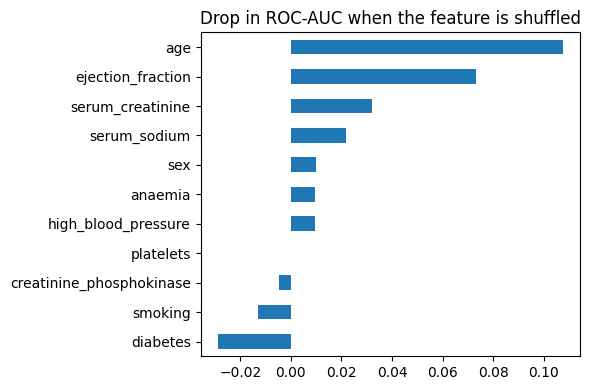

In [ ]:
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                            n_repeats=20, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=features).sort_values()
imp.plot.barh(figsize=(6, 4), title="Drop in ROC-AUC when the feature is shuffled")
plt.tight_layout(); plt.show()

💬 The original paper (Chicco & Jurman, 2020) reported that **ejection fraction and serum creatinine** carry most of the predictive signal. Does your chart agree? Is it plausible medically?

## ⏱ Minutes 42–48 · Turn the model into an app
We save the model, write a small `app.py`, and launch it. The exact same file can be deployed for free later (see the end).

In [ ]:
import joblib, sklearn
medians = X_train.median()
joblib.dump({"model": final_model, "features": features, "medians": medians.to_dict()}, "model.joblib")
with open("requirements.txt", "w") as f:
    f.write(f"gradio\nscikit-learn=={sklearn.__version__}\npandas\njoblib\n")
print("Saved model.joblib and requirements.txt")

Saved model.joblib and requirements.txt


In [ ]:
%%writefile app.py
import joblib
import pandas as pd
import gradio as gr

bundle = joblib.load("model.joblib")
model, features, medians = bundle["model"], bundle["features"], bundle["medians"]

def predict_risk(age, ejection_fraction, serum_creatinine, serum_sodium,
                 high_blood_pressure, anaemia, diabetes, smoking):
    row = dict(medians)  # anything not asked in the form defaults to the training median
    row.update(age=age, ejection_fraction=ejection_fraction,
               serum_creatinine=serum_creatinine, serum_sodium=serum_sodium,
               high_blood_pressure=int(high_blood_pressure), anaemia=int(anaemia),
               diabetes=int(diabetes), smoking=int(smoking))
    p = float(model.predict_proba(pd.DataFrame([row])[features])[:, 1][0])
    band = "🟢 Lower" if p < 0.3 else ("🟡 Moderate" if p < 0.6 else "🔴 Higher")
    note = (f"**{band} risk band** (demo cut-offs). Educational demo trained on 299 patients "
            "from one region. **Not medical advice.**")
    return {"Higher risk": p, "Lower risk": 1 - p}, note

demo = gr.Interface(
    fn=predict_risk,
    inputs=[
        gr.Slider(40, 95, value=60, step=1, label="Age (years)"),
        gr.Slider(10, 80, value=38, step=1, label="Ejection fraction (%)"),
        gr.Slider(0.5, 9.5, value=1.1, step=0.1, label="Serum creatinine (mg/dL)"),
        gr.Slider(113, 148, value=137, step=1, label="Serum sodium (mEq/L)"),
        gr.Checkbox(label="High blood pressure"),
        gr.Checkbox(label="Anaemia"),
        gr.Checkbox(label="Diabetes"),
        gr.Checkbox(label="Smoker"),
    ],
    outputs=[gr.Label(num_top_classes=2, label="Estimated risk"), gr.Markdown()],
    title="Heart Failure Risk Explorer (educational demo)",
    description="Enter a hypothetical patient. The model estimates risk of death during follow-up.",
)

if __name__ == "__main__":
    demo.launch()

Writing app.py


In [ ]:
import importlib, app
importlib.reload(app)
app.demo.launch(share=True)   # prints a public link you can open on your phone (temporary link)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8c1f30b074e4cc65ed.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


✅ **Checkpoint 3 (≈ minute 48):** your app opens, and moving the sliders changes the risk.

**Try:** set ejection fraction to 20 and creatinine to 3.0. Does the risk go up? Does that match what you saw in the plots?

## ⏱ Minutes 48–52 · Auto-generate your model card (your README for GitHub)

In [ ]:
pred_final = (proba >= THRESHOLD).astype(int)
auc = roc_auc_score(y_test, proba)
rec = recall_score(y_test, pred_final)
prec = precision_score(y_test, pred_final, zero_division=0)
cv_auc = cv_table.loc[BEST, "ROC-AUC (mean)"]

MY_NAME = "Your Name"   # 👈 YOUR TURN #4

card = f"""# Heart Failure Risk Explorer
Educational ML project by {MY_NAME}. **Not for clinical use.**

## What it does
Predicts risk of death during follow-up for heart-failure patients from routine clinical measurements, and serves the model through a small Gradio web app.

## Data
UCI *Heart Failure Clinical Records* (299 patients, 12 features), CC BY 4.0. Chicco & Jurman (2020), BMC Med Inform Decis Mak 20:16.

## Method
- Stratified 80/20 train/test split; 5-fold cross-validation for model comparison.
- Follow-up `time` {"INCLUDED" if USE_FOLLOWUP_TIME else "excluded"} (it leaks the outcome: it is not known at prediction time).
- Model: {BEST}.

## Results (held-out test set, threshold {THRESHOLD})
| Metric | Value |
|---|---|
| ROC-AUC (test) | {auc:.2f} |
| ROC-AUC (5-fold CV mean) | {cv_auc:.2f} |
| Recall (deaths caught) | {rec:.2f} |
| Precision | {prec:.2f} |

## Limitations
- Only 299 patients from a single region and time period; results may not generalize.
- Small test set, so metrics are noisy.
- Association, not causation. Never use for real medical decisions.

## Run it
`pip install -r requirements.txt && python app.py`
"""
with open("README.md", "w") as f:
    f.write(card)
print(card)

# Heart Failure Risk Explorer
Educational ML project by Your Name. **Not for clinical use.**

## What it does
Predicts risk of death during follow-up for heart-failure patients from routine clinical measurements, and serves the model through a small Gradio web app.

## Data
UCI *Heart Failure Clinical Records* (299 patients, 12 features), CC BY 4.0. Chicco & Jurman (2020), BMC Med Inform Decis Mak 20:16.

## Method
- Stratified 80/20 train/test split; 5-fold cross-validation for model comparison.
- Follow-up `time` excluded (it leaks the outcome: it is not known at prediction time).
- Model: Logistic Regression.

## Results (held-out test set, threshold 0.5)
| Metric | Value |
|---|---|
| ROC-AUC (test) | 0.73 |
| ROC-AUC (5-fold CV mean) | 0.77 |
| Recall (deaths caught) | 0.53 |
| Precision | 0.53 |

## Limitations
- Only 299 patients from a single region and time period; results may not generalize.
- Small test set, so metrics are noisy.
- Association, not causation. Never use for r

## ⏱ Final minutes (and at home) · Ship it (this is what makes it a resume project)
1. **GitHub:** in Colab, *File → Save a copy in GitHub*. Also upload `README.md`, `app.py`, `model.joblib`, `requirements.txt` (Files panel → download each).
2. **(Optional, 5 min, free) permanent demo link:** create a Space at huggingface.co/spaces (SDK: Gradio, hardware: CPU basic) and upload `app.py`, `model.joblib`, `requirements.txt`.
3. **Resume bullet template:**
   > *Built and deployed an ML risk-prediction web app on 299 real heart-failure patient records (scikit-learn, Gradio); compared logistic regression vs. random forest with 5-fold CV (ROC-AUC __), identified and removed a data-leakage feature, and documented limitations in a model card.*

## 🚀 Challenge menu (pick any after the session)
1. Set `USE_FOLLOWUP_TIME = True` and explain the jump in performance.
2. Add a third model and tune it with `GridSearchCV`.
3. Add a calibration plot (`sklearn.calibration.calibration_curve`): when the model says 70%, is it right ~70% of the time?
4. Move up to the **Advanced track** (hospital readmissions, 100k patients, fairness audit).